# The Transition Has Two Speeds

**What we are doing:** use electricity and coal data to decide which energy industries deserve more investment.

**How to use this notebook:** choose **Runtime → Run all**. If asked, upload the three CSVs from the project's `data` folder. Each graph now appears immediately beneath its code, followed by a short explanation. The download cell is at the very end so the ZIP includes the extra summary and correlation results.

**What the words mean:** demand = electricity people need; generation = electricity produced; clean = renewables plus nuclear; fossil = coal, gas and oil. A TWh measures an amount of electricity. Overweight = give an industry a larger portfolio share; neutral = keep its normal share.

**Working recommendation:** overweight clean electricity generation and neutral U.S. thermal coal over 24–36 months. This is our interpretation of historical evidence; company profitability and valuation still need consideration.

If Colab disconnects, the uploaded CSVs may disappear. Running all cells again will ask for any missing files. Previously saved graphs remain visible in the notebook.


In [ ]:
from pathlib import Path

REQUIRED_CSVS = [
    'country_year_electricity_2020_2025.csv',
    'eia_coal_consumption_quality_2020_2025.csv',
    'eia_state_generation_2020_2025.csv',
]
search_folders = [Path.cwd() / 'data', Path.cwd(), Path('/content')]
missing_csvs = [name for name in REQUIRED_CSVS
                if not any((folder / name).is_file() for folder in search_folders)]
if missing_csvs:
    print('Files needed:', ', '.join(missing_csvs))
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Put the three CSVs in the data folder beside this notebook.') from exc
    uploaded = files.upload()
    still_missing = [name for name in REQUIRED_CSVS
                     if not any((folder / name).is_file() for folder in search_folders)]
    if still_missing:
        raise FileNotFoundError('Upload these exact filenames: ' + ', '.join(still_missing))
else:
    print('All three CSVs are already available. No upload needed.')


All three CSVs are already available. No upload needed.


## Setup: load the files

This cell loads the three spreadsheets and prepares the chart tools. It also defines `ROOT` (the working folder) and `OUT` (the folder where charts and tables are saved). Run this before the analysis cells.


In [ ]:
from pathlib import Path
import hashlib
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image as NotebookImage

ROOT = Path.cwd()
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'
OUT.mkdir(parents=True, exist_ok=True)
TEAL, COAL, GOLD, BLUE, GRAY = '#087F8C', '#343F4B', '#D99A20', '#537AA5', '#6B7280'
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':13,
    'axes.spines.top':False, 'axes.spines.right':False, 'axes.titleweight':'bold',
    'axes.titlesize':17, 'figure.facecolor':'white', 'axes.labelcolor':COAL,
    'text.color':COAL, 'xtick.color':COAL, 'ytick.color':COAL,
    'savefig.facecolor':'white'})

def locate(name):
    for parent in [DATA, ROOT, Path('/content')]:
        if (parent / name).exists():
            return parent / name
    raise FileNotFoundError(f'Upload {name} to Colab, or put it in the data folder.')

def export_table(frame, name, index=False):
    frame.to_csv(OUT / f'{name}.csv', index=index)

def save(fig, name, note):
    fig.text(.02, .022, note, fontsize=10, color=GRAY, ha='left', va='bottom')
    fig.subplots_adjust(bottom=.19, top=.86)
    fig.savefig(OUT / f'{name}.png', dpi=190, bbox_inches='tight')
    fig.savefig(OUT / f'{name}.svg', bbox_inches='tight')
    plt.close(fig)
    display(NotebookImage(filename=str(OUT / f'{name}.png'), width=1100))

def pct(new, old):
    return float((new / old - 1) * 100)

power_path = locate('country_year_electricity_2020_2025.csv')
coal_path = locate('eia_coal_consumption_quality_2020_2025.csv')
third_path = locate('eia_state_generation_2020_2025.csv')
power = pd.read_csv(power_path)
coal = pd.read_csv(coal_path, dtype={'location':str})
third = pd.read_csv(third_path)


print(f'Loaded {len(power):,} electricity rows, {len(coal):,} coal rows, and {len(third):,} extra generation rows.')


Loaded 1,138 electricity rows, 1,750 coal rows, and 12,802 extra generation rows.


## Audit before analysis

Country counts change sharply in 2025. We use the same 91 countries in every year for the main comparison. The 196-country 2020–2024 sensitivity is exported separately. Coal volumes are short tons, despite the guide’s description. Heat-content calculations are excluded because the units metadata and cross-sector scales conflict.

In [ ]:
assert not power.duplicated(['iso3','year']).any(), 'Duplicate country-years need investigation.'
assert not coal.duplicated(['location','sector','period']).any(), 'Duplicate EIA keys.'
assert not third.duplicated(['year','state','producer','fuel']).any(), 'Duplicate third-data keys.'
assert set(coal['consumption-units']) == {'short tons'}, 'Recheck tonnage units.'
assert set(coal['stocks-units']) == {'short tons'}, 'Recheck stocks units.'
assert set(coal['receipts-units']) == {'short tons'}, 'Recheck receipts units.'
assert set(coal['price-units']) == {'dollars per short ton'}, 'Recheck price units.'
assert np.allclose(power.generation_twh,
    power.clean_generation_twh + power.fossil_generation_twh, atol=.03)
assert np.allclose(power.demand_twh,
    power.generation_twh + power.net_imports_twh, atol=.03)
assert not power[['generation_twh','clean_generation_twh','fossil_generation_twh']].lt(0).any().any()

coverage = power.groupby('year').agg(countries=('iso3','nunique'),
    generation_twh=('generation_twh','sum'), fossil_twh=('fossil_generation_twh','sum'))
export_table(coverage, 'country_coverage', index=True)
missing = pd.concat([power.isna().sum().rename('Ember'),
    coal.isna().sum().rename('EIA_coal')], axis=1)
export_table(missing, 'missing_values', index=True)

# The provided heat-content units are wrong and the numeric scale changes by sector.
# We deliberately do not infer a conversion or use heat content in investment claims.
heat_audit = coal.groupby('sectorDescription')['heat-content'].agg(['min','median','max'])
export_table(heat_audit, 'heat_content_excluded_audit', index=True)

years = list(range(2020,2026))
country_counts = power[power.year.isin(years)].groupby('iso3').year.nunique()
panel_ids = country_counts[country_counts.eq(len(years))].index
panel = power[power.iso3.isin(panel_ids) & power.year.isin(years)].copy()
assert len(panel_ids) == 91, 'The delivered snapshot changed; review coverage.'
# All 213 identifiers in this supplied snapshot represent countries/territories;
# no World, continent, EU, or other aggregate rows are included.
export_table(panel[['iso3','country']].drop_duplicates().sort_values('iso3'), 'balanced_panel_members')

totals_cols = ['generation_twh','demand_twh','clean_generation_twh',
    'fossil_generation_twh','wind_solar_generation_twh','net_imports_twh']
global_panel = panel.groupby('year')[totals_cols].sum(min_count=1)
global_panel['clean_share_pct'] = 100 * global_panel.clean_generation_twh / global_panel.generation_twh
export_table(global_panel, 'balanced_91_country_totals', index=True)
coverage_share = 100 * global_panel.loc[2024,'generation_twh'] / coverage.loc[2024,'generation_twh']
naive_fossil_change = pct(coverage.loc[2025,'fossil_twh'],coverage.loc[2024,'fossil_twh'])
matched_fossil_change = pct(global_panel.loc[2025,'fossil_generation_twh'],global_panel.loc[2024,'fossil_generation_twh'])


print('Data checks passed. The main analysis uses the same 91 countries in every year.')
display(coverage[['countries']].rename(columns={'countries':'Countries available'}))


Data checks passed. The main analysis uses the same 91 countries in every year.


,Countries available
year,
2020,213
2021,213
2022,213
2023,212
2024,196
2025,91


## Graph 1: check that the countries match

We first check whether missing countries could distort the comparison.


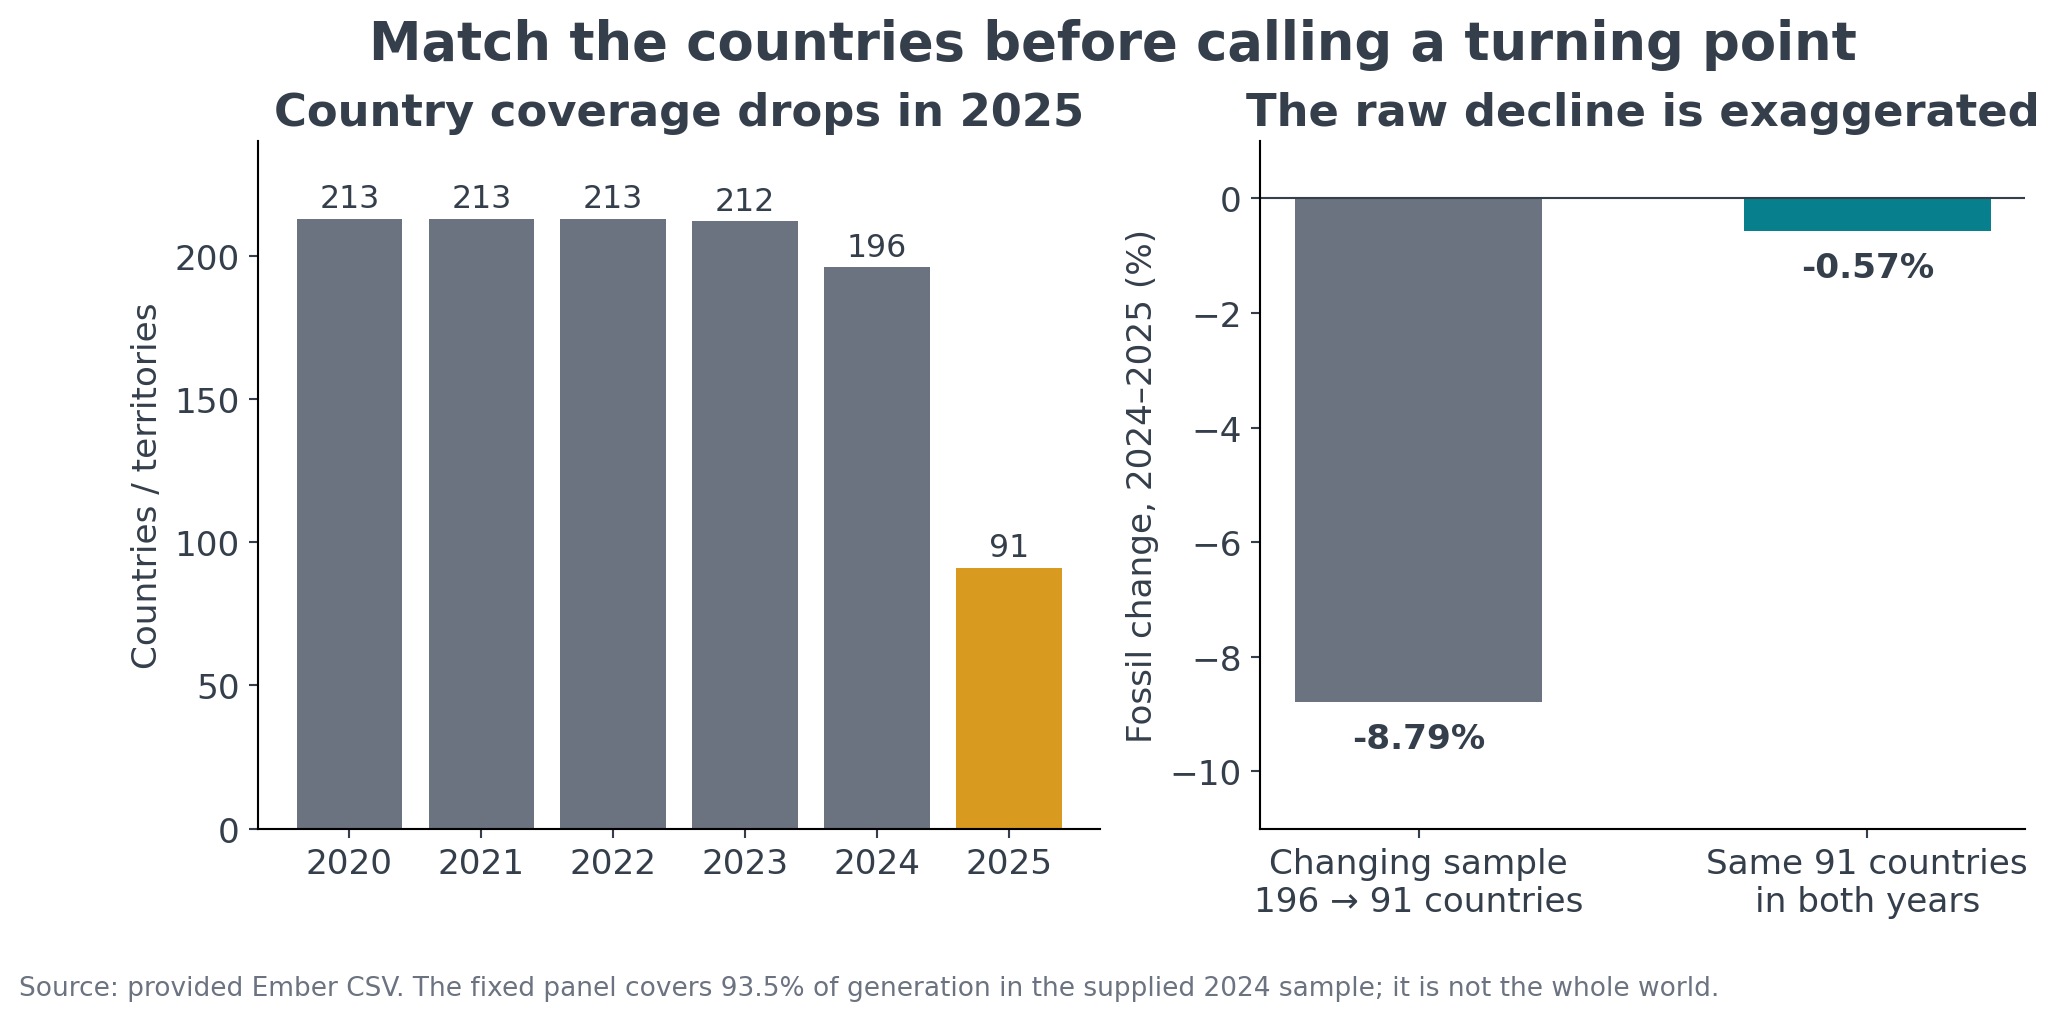

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(12,5.4),gridspec_kw={'width_ratios':[1.1,1]})
ax[0].bar(coverage.index, coverage.countries, color=[GRAY]*5+[GOLD])
for y,n in coverage.countries.items(): ax[0].text(y,n+4,str(n),ha='center',fontsize=12)
ax[0].set(ylim=(0,240),ylabel='Countries / territories',title='Country coverage drops in 2025')
vals = [naive_fossil_change,matched_fossil_change]
ax[1].bar(['Changing sample\n196 → 91 countries','Same 91 countries\nin both years'],vals,color=[GRAY,TEAL],width=.55)
for i,v in enumerate(vals): ax[1].text(i,v-.35,f'{v:.2f}%',va='top',ha='center',fontweight='bold')
ax[1].set(ylim=(-11,1),ylabel='Fossil change, 2024–2025 (%)',title='The raw decline is exaggerated')
ax[1].axhline(0,color=COAL,lw=.8)
fig.suptitle('Match the countries before calling a turning point',fontsize=20,fontweight='bold')
save(fig,'01_coverage_bias',f'Source: provided Ember CSV. The fixed panel covers {coverage_share:.1f}% of generation in the supplied 2024 sample; it is not the whole world.')



**Read this graph:** the left panel counts countries with data. The right panel compares two ways of measuring the 2025 fossil change.

**What it means:** comparing different country groups makes the decline look much larger. Comparing the same 91 countries gives about **0.57%**, rather than **8.79%**.

**For the presentation:** call this a fixed 91-country panel. It is not a measurement of the whole world.

## Graph 2: compare clean growth, fossil growth and demand

This is the main graph for understanding the project. The sensitivity table also checks different starting years.


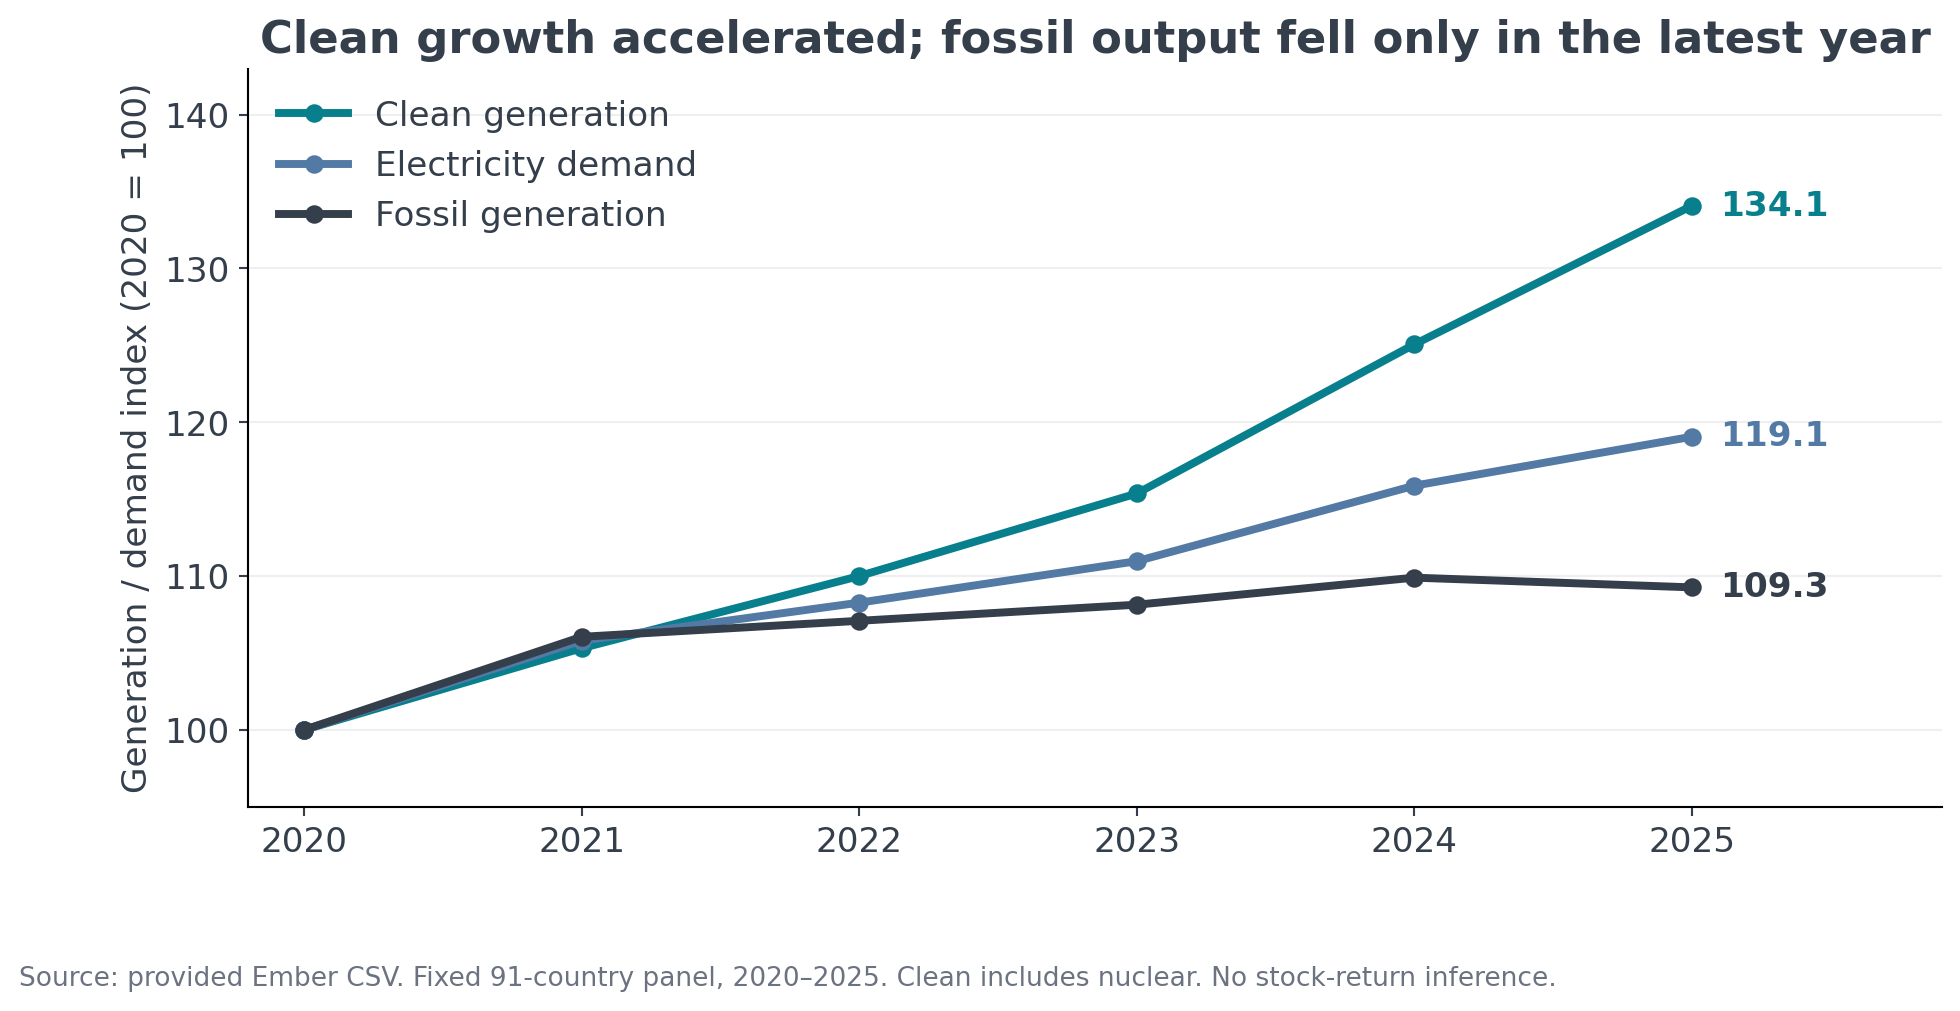

In [ ]:
fig, ax = plt.subplots(figsize=(11.5,5.8))
for col,label,color in [('clean_generation_twh','Clean generation',TEAL),
                       ('demand_twh','Electricity demand',BLUE),
                       ('fossil_generation_twh','Fossil generation',COAL)]:
    indexed=100*global_panel[col]/global_panel.loc[2020,col]
    ax.plot(indexed.index,indexed,marker='o',lw=3,color=color,label=label)
    ax.text(2025.1,indexed.iloc[-1],f'{indexed.iloc[-1]:.1f}',va='center',color=color,fontweight='bold')
ax.set(xlim=(2019.8,2025.9),ylim=(95,143),ylabel='Generation / demand index (2020 = 100)',
    title='Clean growth accelerated; fossil output fell only in the latest year')
ax.legend(frameon=False,loc='upper left')
ax.grid(axis='y',alpha=.2)
save(fig,'02_balanced_panel_trends','Source: provided Ember CSV. Fixed 91-country panel, 2020–2025. Clean includes nuclear. No stock-return inference.')

sensitivity=[]
for end in [2024,2025]:
    selected=power[power.year.between(2020,end)]
    counts=selected.groupby('iso3').year.nunique()
    ids=counts[counts.eq(end-2019)].index
    agg=selected[selected.iso3.isin(ids)].groupby('year')[totals_cols].sum(min_count=1)
    for start in [2020,2021,2022]:
        sensitivity.append({'start':start,'end':end,'countries':len(ids),
            'clean_change_pct':pct(agg.loc[end,'clean_generation_twh'],agg.loc[start,'clean_generation_twh']),
            'fossil_change_pct':pct(agg.loc[end,'fossil_generation_twh'],agg.loc[start,'fossil_generation_twh'])})
export_table(pd.DataFrame(sensitivity),'start_end_year_sensitivity')



**Read this graph:** every line starts at 100 in 2020. Ending at 134 means growth of 34%.

**What it means:** clean electricity rose about **34%**, demand about **19%**, and fossil electricity about **9%** in the same countries. Fossil output fell slightly in 2025, but remained above 2020.

**For the presentation:** clean power can grow quickly while fossil power remains important. Rising demand helps explain how both can grow.

## Graph 3: compare the largest electricity markets

The three countries are selected because they were the largest producers in 2024, before looking at their 2025 outcomes.


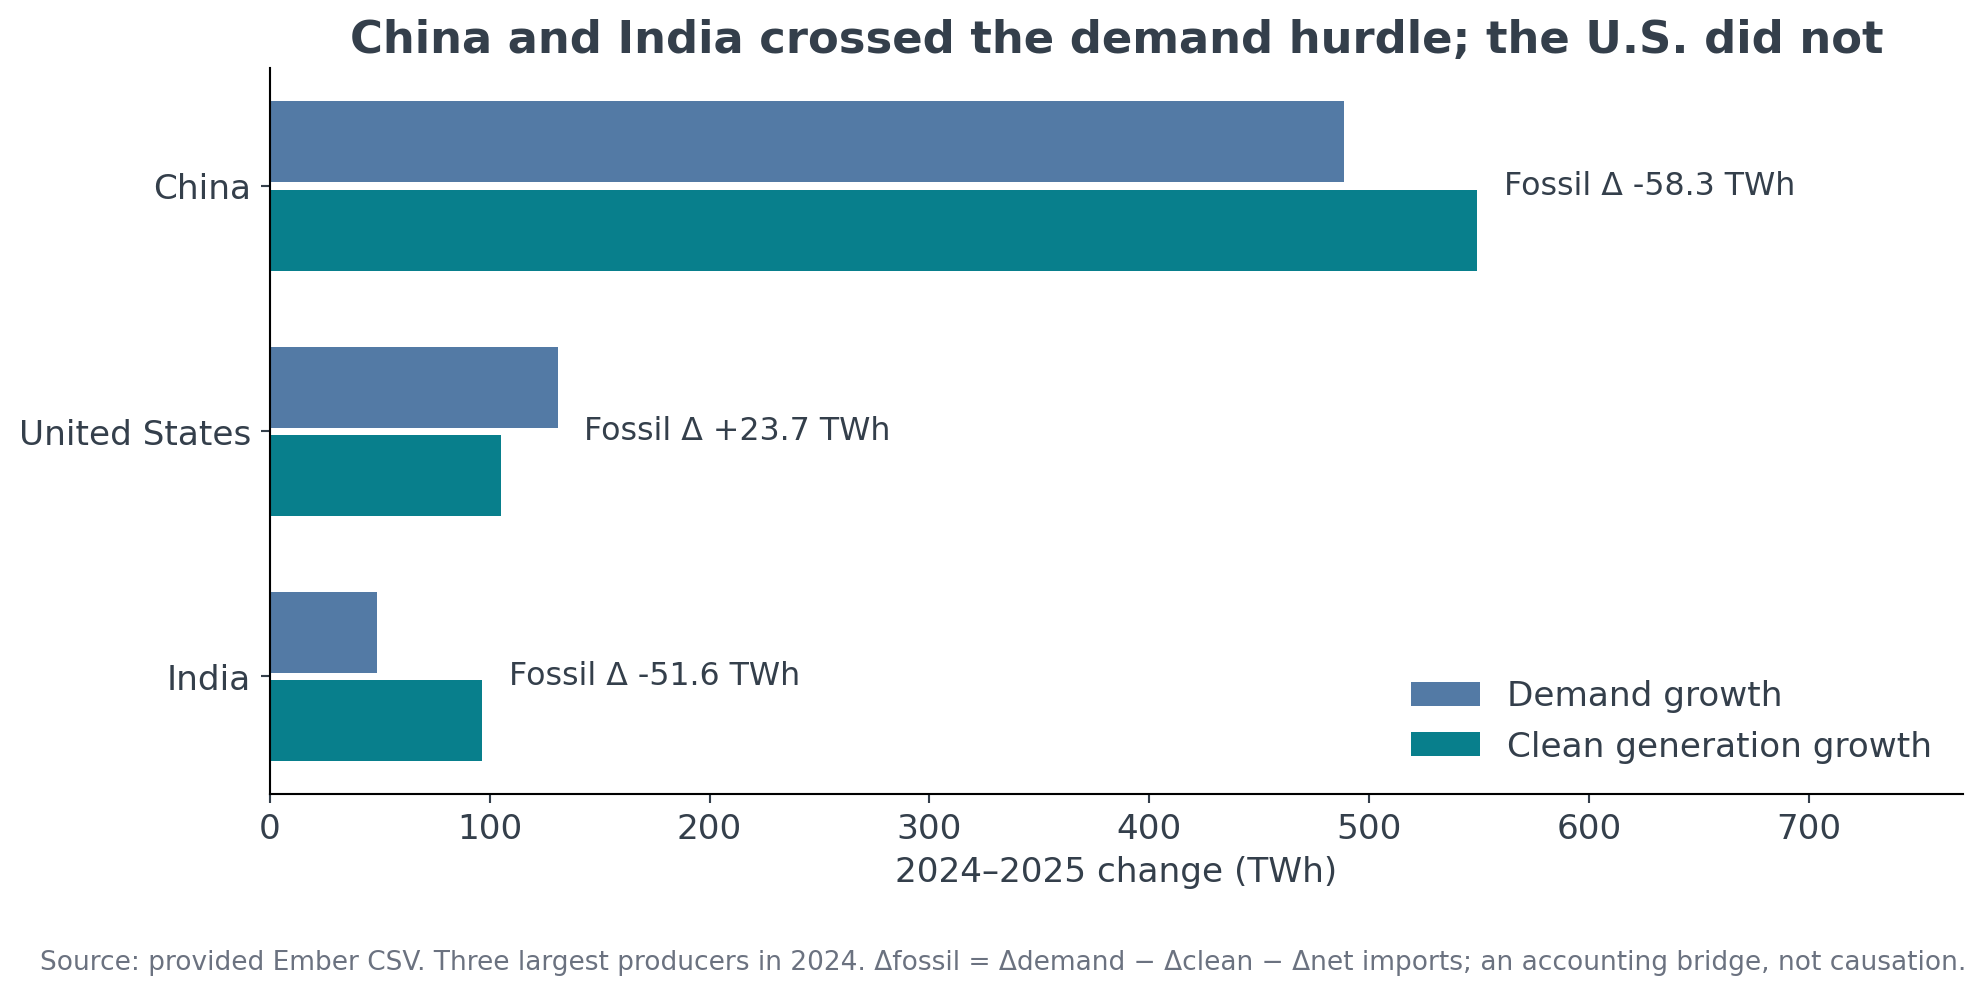

In [ ]:
power = power.sort_values(['iso3','year']).copy()
country_groups = power.groupby('iso3',sort=False)
for col in totals_cols:
    power['delta_'+col] = country_groups[col].diff().where(country_groups.year.diff().eq(1))
# Recompute within-file changes; do not use supplied 2020 changes that require unseen 2019 data.
comparison = power[power.year.eq(2025)].copy()
comparison['demand_surplus_twh'] = comparison.delta_clean_generation_twh-comparison.delta_demand_twh
comparison['identity_residual_twh'] = (comparison.delta_fossil_generation_twh
    +comparison.demand_surplus_twh+comparison.delta_net_imports_twh)
assert comparison.identity_residual_twh.abs().max() < .03
export_table(comparison,'country_2025_changes')
# Select the three largest producers in 2024 rather than selecting on outcomes.
top3=power[power.year.eq(2024)].nlargest(3,'generation_twh').iso3.tolist()
leaders=comparison.set_index('iso3').loc[top3]
labels=[{'CHN':'China','USA':'United States','IND':'India'}.get(i,i) for i in leaders.index]
fig, ax = plt.subplots(figsize=(11.5,5.7))
pos=np.arange(len(leaders))
ax.barh(pos-.18,leaders.delta_demand_twh,height=.33,color=BLUE,label='Demand growth')
ax.barh(pos+.18,leaders.delta_clean_generation_twh,height=.33,color=TEAL,label='Clean generation growth')
for i,(_,r) in enumerate(leaders.iterrows()):
    ax.text(max(r.delta_demand_twh,r.delta_clean_generation_twh)+12,i,
        f'Fossil Δ {r.delta_fossil_generation_twh:+.1f} TWh',va='center',fontsize=12)
ax.set(yticks=pos,yticklabels=labels,xlim=(0,770),xlabel='2024–2025 change (TWh)',
    title='China and India crossed the demand hurdle; the U.S. did not')
ax.invert_yaxis(); ax.legend(frameon=False,loc='lower right')
save(fig,'03_country_divergence','Source: provided Ember CSV. Three largest producers in 2024. Δfossil = Δdemand − Δclean − Δnet imports; an accounting bridge, not causation.')


**Read this graph:** compare each country's demand-growth bar with its clean-generation-growth bar. The fossil change is written beside the bars.

**What it means:** clean additions exceeded new demand in China and India in 2025. In the U.S., clean additions covered only about **80%** of new demand, and fossil output increased.

**One detail:** imports also affect the balance. Fossil change = demand change − clean change − net import change. This describes the electricity balance; it does not prove causation.

## Graph 4: see what happened to U.S. coal

Use U.S. Total, Electric Power sector 98 only. It already includes utilities and independent power producers.


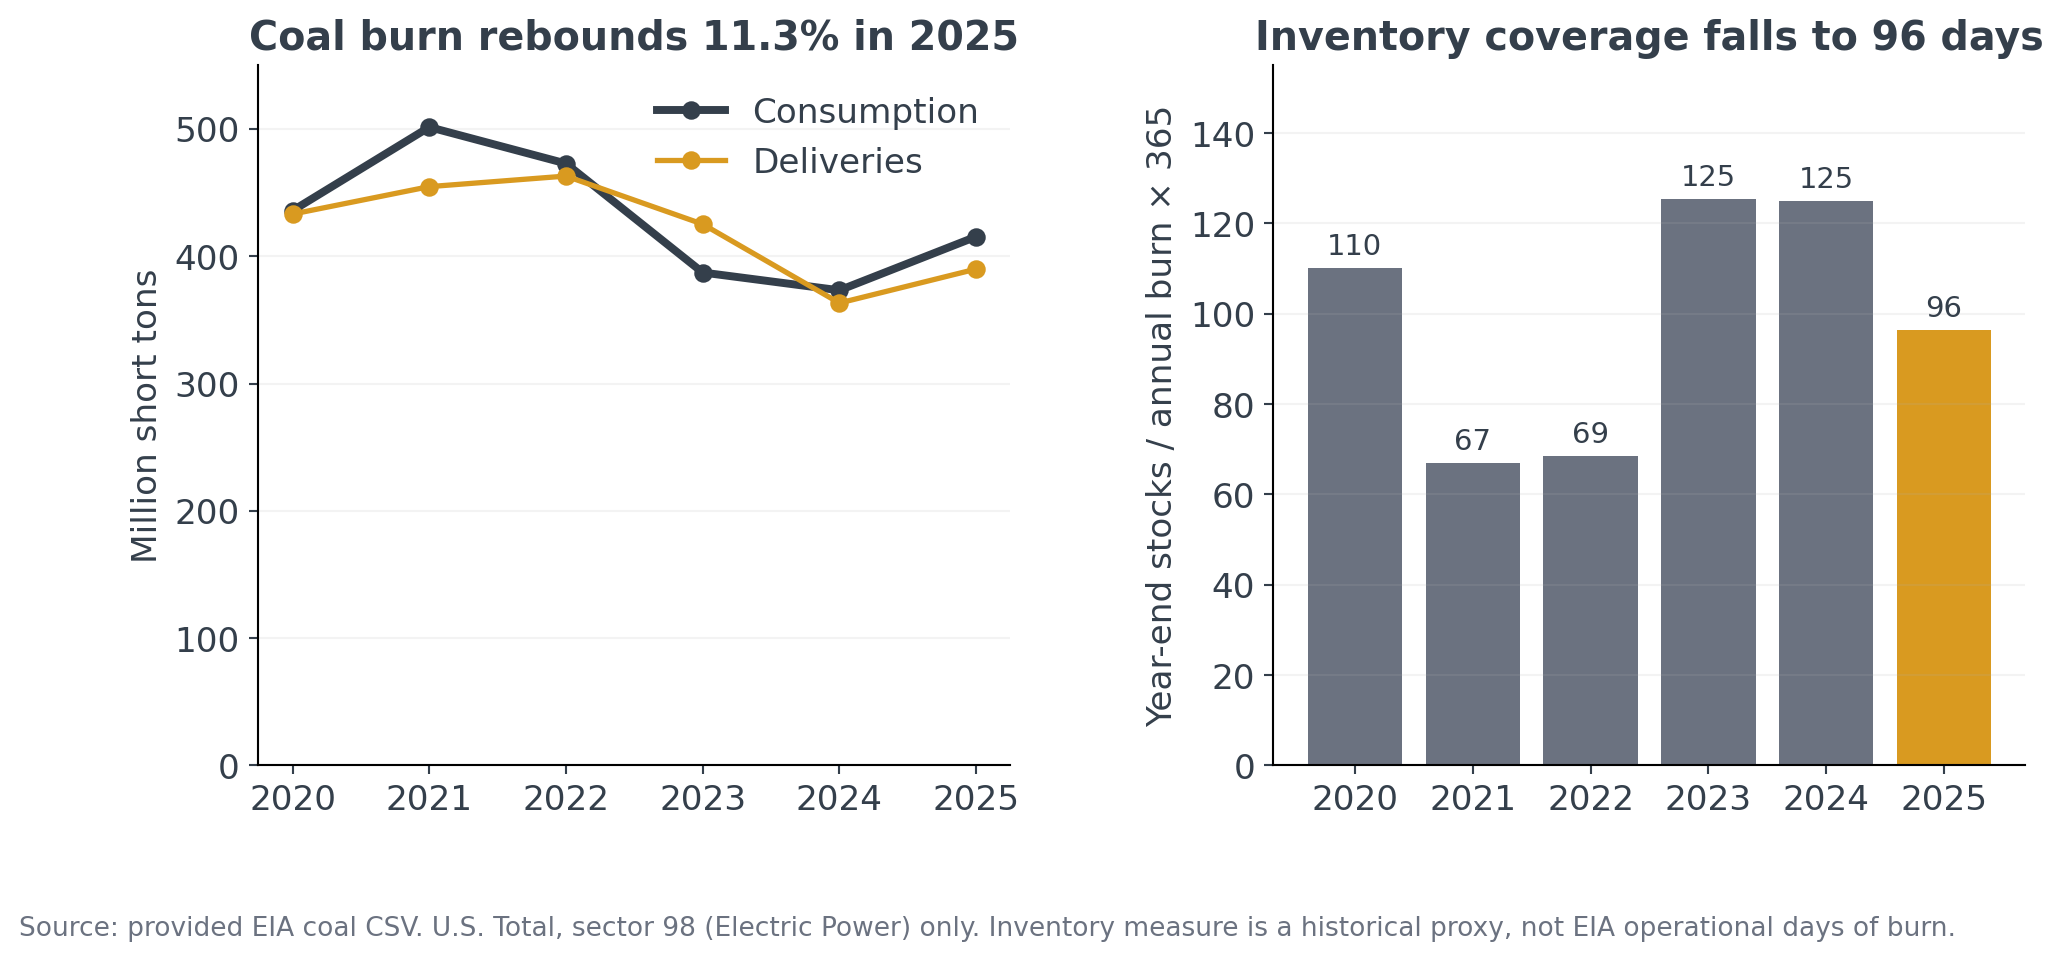

In [ ]:
us_coal=coal[coal.location.eq('US') & coal.sector.eq(98)].set_index('period').sort_index().copy()
assert len(us_coal)==6
us_coal['inventory_days_proxy']=365*us_coal.stocks/us_coal.consumption
export_table(us_coal[['consumption','receipts','stocks','price','inventory_days_proxy']], 'us_electric_power_coal', index=True)
state_codes=set('AL AK AZ AR CA CO CT DE DC FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY'.split())
state_coal=coal[coal.location.isin(state_codes) & coal.sector.eq(98)].copy()
# Reconciliation checks the selected geography and sector. Missing state records
# remain missing and are not silently imputed to zero.
assert np.allclose(state_coal.groupby('period').consumption.sum(min_count=1),us_coal.consumption,atol=.1)
components=coal[coal.location.eq('US') & coal.sector.isin([1,94])].groupby('period').consumption.sum(min_count=1)
assert np.allclose(components,us_coal.consumption,atol=.1)
fig, ax=plt.subplots(1,2,figsize=(12,5.5))
ax[0].plot(us_coal.index,us_coal.consumption/1e6,color=COAL,marker='o',lw=3,label='Consumption')
ax[0].plot(us_coal.index,us_coal.receipts/1e6,color=GOLD,marker='o',lw=2,label='Deliveries')
ax[0].set(ylim=(0,550),ylabel='Million short tons',title='Coal burn rebounds 11.3% in 2025')
ax[0].set_title('Coal burn rebounds 11.3% in 2025',fontsize=15)
ax[0].legend(frameon=False)
ax[1].bar(us_coal.index,us_coal.inventory_days_proxy,color=[GRAY]*5+[GOLD])
for y,v in us_coal.inventory_days_proxy.items(): ax[1].text(y,v+3,f'{v:.0f}',ha='center',fontsize=11)
ax[1].set(ylim=(0,155),ylabel='Year-end stocks / annual burn × 365',title='Inventory coverage falls to 96 days')
ax[1].set_title('Inventory coverage falls to 96 days',fontsize=15)
fig.subplots_adjust(wspace=.35)
for a in ax: a.grid(axis='y',alpha=.15)
save(fig,'04_coal_and_inventory','Source: provided EIA coal CSV. U.S. Total, sector 98 (Electric Power) only. Inventory measure is a historical proxy, not EIA operational days of burn.')



**Read this graph:** the left panel shows coal burned and delivered to U.S. power plants. The right panel compares year-end stocks with that year's coal use.

**What it means:** coal use rebounded **11.3%** in 2025, while stocks fell. The stocks-to-use proxy fell from about **125 to 96 days**.

**For the presentation:** this is evidence against assuming coal declines smoothly every year. The 96-day figure is a historical ratio, not a prediction of when plants will run out of coal.

## Graph 5: separate coal from natural gas

Extra source: EIA Historical State Data, https://www.eia.gov/electricity/data/state/ . We use its U.S. Total Electric Power Industry series. Its generation totals stay separate from Ember because coverage differs.


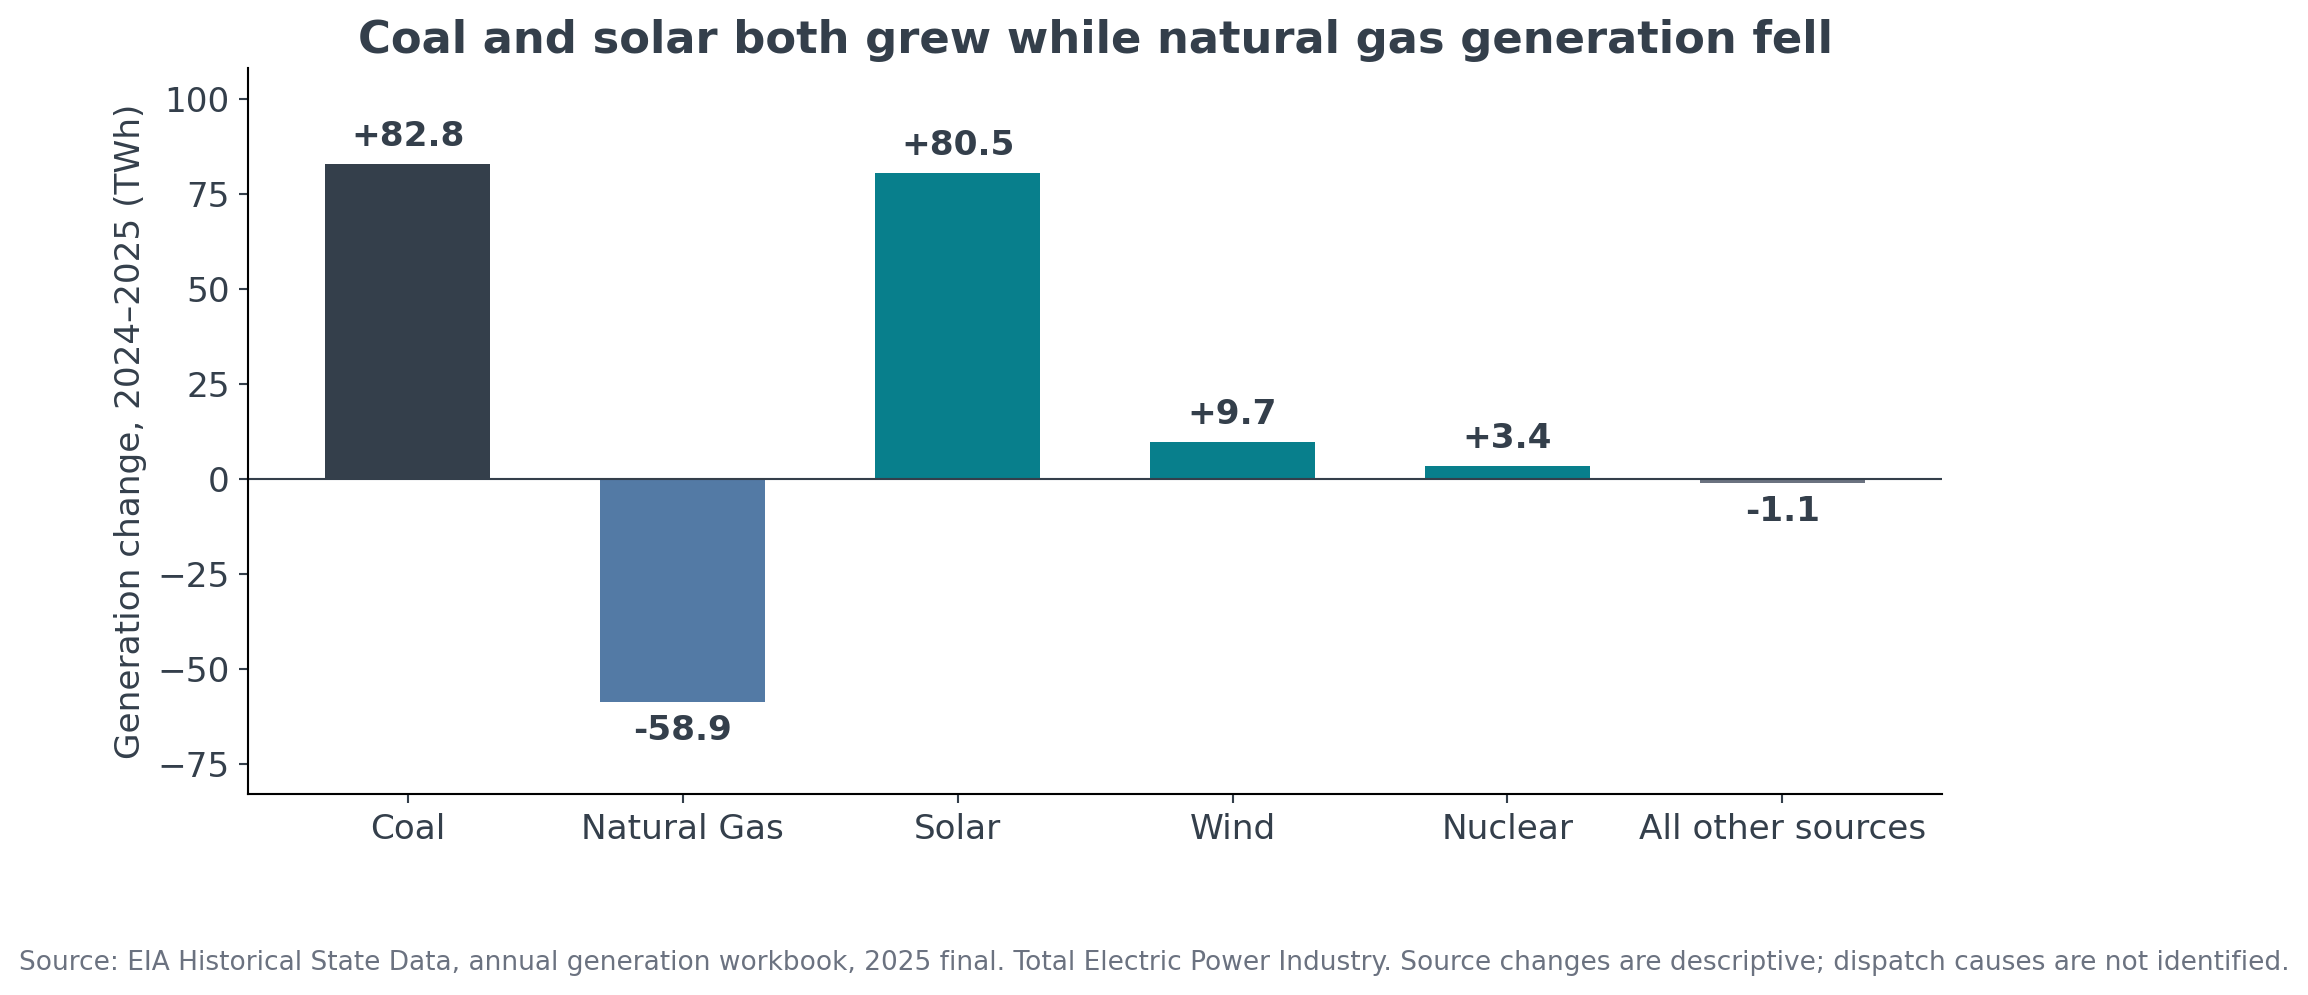

In [ ]:
# Keep the external EIA generation series separate from Ember totals: survey
# scope and revisions differ. This chart uses one EIA producer total only.
us_gen=third[third.state.str.upper().eq('US-TOTAL') &
    third.producer.eq('Total Electric Power Industry')].pivot(index='year',columns='fuel',values='generation_mwh')/1e6
delta=us_gen.loc[2025]-us_gen.loc[2024]
fuels=['Coal','Natural Gas','Solar Thermal and Photovoltaic','Wind','Nuclear']
fuel_delta=delta.reindex(fuels).rename(index={'Solar Thermal and Photovoltaic':'Solar'})
fuel_delta.loc['All other sources']=delta['Total']-fuel_delta.sum()
export_table(us_gen,'external_eia_us_generation_twh',index=True)
export_table(fuel_delta.rename('change_twh').to_frame(),'external_eia_2025_fuel_changes',index=True)
fig,ax=plt.subplots(figsize=(11.5,5.7))
colors=[COAL,BLUE,TEAL,TEAL,TEAL,GRAY]
bars=ax.bar(fuel_delta.index,fuel_delta,color=colors,width=.6)
for b,v in zip(bars,fuel_delta):
    ax.text(b.get_x()+b.get_width()/2,v+(3 if v>=0 else -3),f'{v:+.1f}',
        ha='center',va='bottom' if v>=0 else 'top',fontweight='bold')
ax.axhline(0,color=COAL,lw=.8)
ax.set(ylim=(-83,108),ylabel='Generation change, 2024–2025 (TWh)',
    title='Coal and solar both grew while natural gas generation fell')
save(fig,'05_external_fuel_mix','Source: EIA Historical State Data, annual generation workbook, 2025 final. Total Electric Power Industry. Source changes are descriptive; dispatch causes are not identified.')



**Read this graph:** bars above zero mean more electricity from that source in 2025; bars below zero mean less.

**What it means:** U.S. coal generation increased about **82.8 TWh**, solar increased **80.5 TWh**, and gas decreased **58.9 TWh** in this EIA series.

**For the presentation:** coal and solar grew together. This extra dataset separates coal from gas, which the original Ember fossil total cannot do. The bars alone do not identify why generation shifted.

## Graph 6: test a simple what-if scenario

The next graph tests assumptions about electricity demand and clean additions. It is not a prediction.


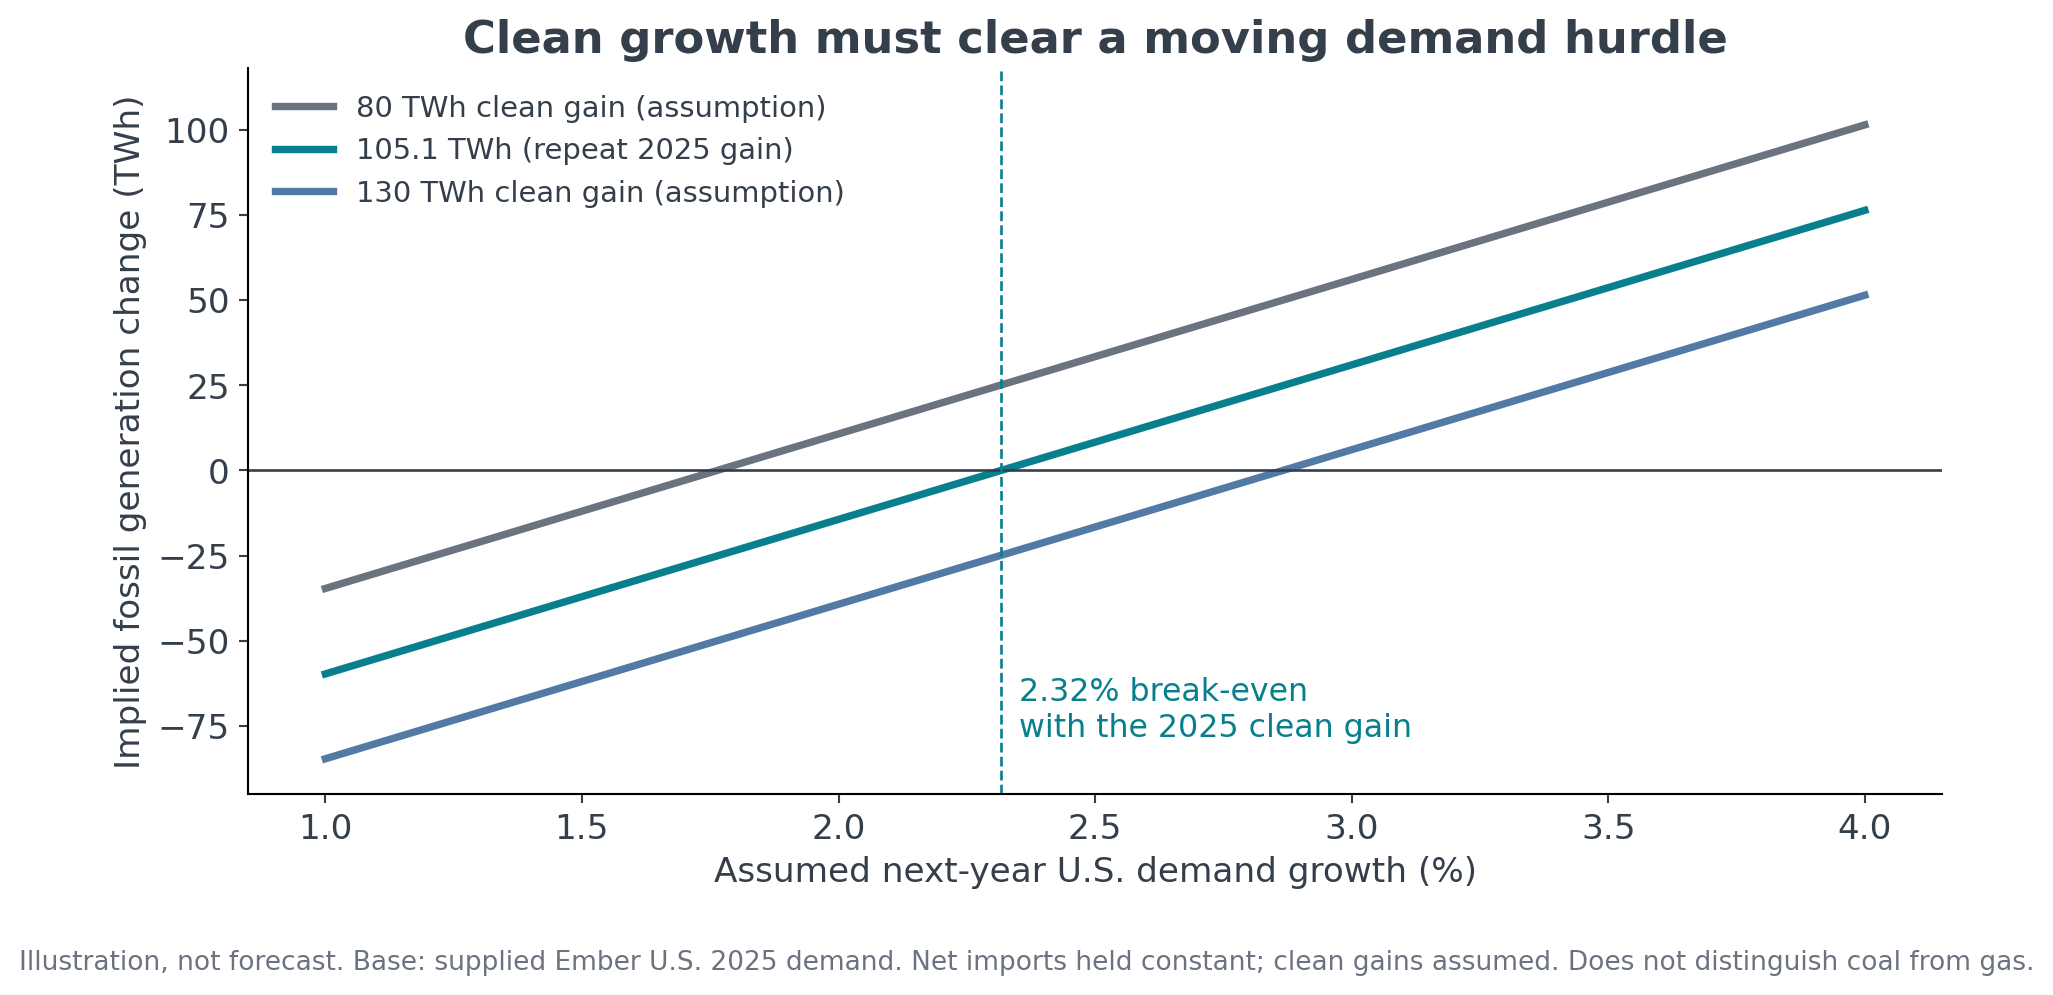

In [ ]:
us_power=power[power.iso3.eq('USA')].set_index('year').sort_index()
base_demand=us_power.loc[2025,'demand_twh']
latest_clean_gain=us_power.loc[2025,'delta_clean_generation_twh']
breakeven=100*latest_clean_gain/base_demand
rates=np.array([1,1.5,2,2.5,3,3.5,4])
scenarios=[]
fig,ax=plt.subplots(figsize=(11.5,5.7))
for gain,label,color in [(80,'80 TWh clean gain (assumption)',GRAY),
        (latest_clean_gain,f'{latest_clean_gain:.1f} TWh (repeat 2025 gain)',TEAL),
        (130,'130 TWh clean gain (assumption)',BLUE)]:
    change=base_demand*rates/100-gain
    ax.plot(rates,change,color=color,lw=2.8,label=label)
    for rate,ch in zip(rates,change): scenarios.append({'demand_growth_pct':rate,'clean_gain_twh':gain,'fossil_change_twh':ch})
ax.axhline(0,color=COAL,lw=1)
ax.axvline(breakeven,color=TEAL,ls='--',lw=1)
ax.text(breakeven+.035,-78,f'{breakeven:.2f}% break-even\nwith the 2025 clean gain',color=TEAL,fontsize=12)
ax.set(xlabel='Assumed next-year U.S. demand growth (%)',ylabel='Implied fossil generation change (TWh)',
    title='Clean growth must clear a moving demand hurdle',ylim=(-95,118))
ax.legend(frameon=False,loc='upper left',fontsize=11)
save(fig,'06_us_demand_scenarios','Illustration, not forecast. Base: supplied Ember U.S. 2025 demand. Net imports held constant; clean gains assumed. Does not distinguish coal from gas.')
export_table(pd.DataFrame(scenarios),'illustrative_us_scenarios')



**Read this graph:** choose an assumed demand growth rate along the bottom. Each line assumes a different amount of new clean electricity. Above zero means fossil generation would need to rise; below zero means it would fall.

**What it means:** if clean additions repeated 2025's 105.1 TWh and net imports stayed unchanged, demand growth of about **2.32%** would leave fossil generation flat.

**For the presentation:** this is a what-if calculation, not a forecast. Different demand, imports or clean additions produce different results.

## Appendix: which states increased coal use?

This is extra detail for questions; it can go in the presentation appendix.


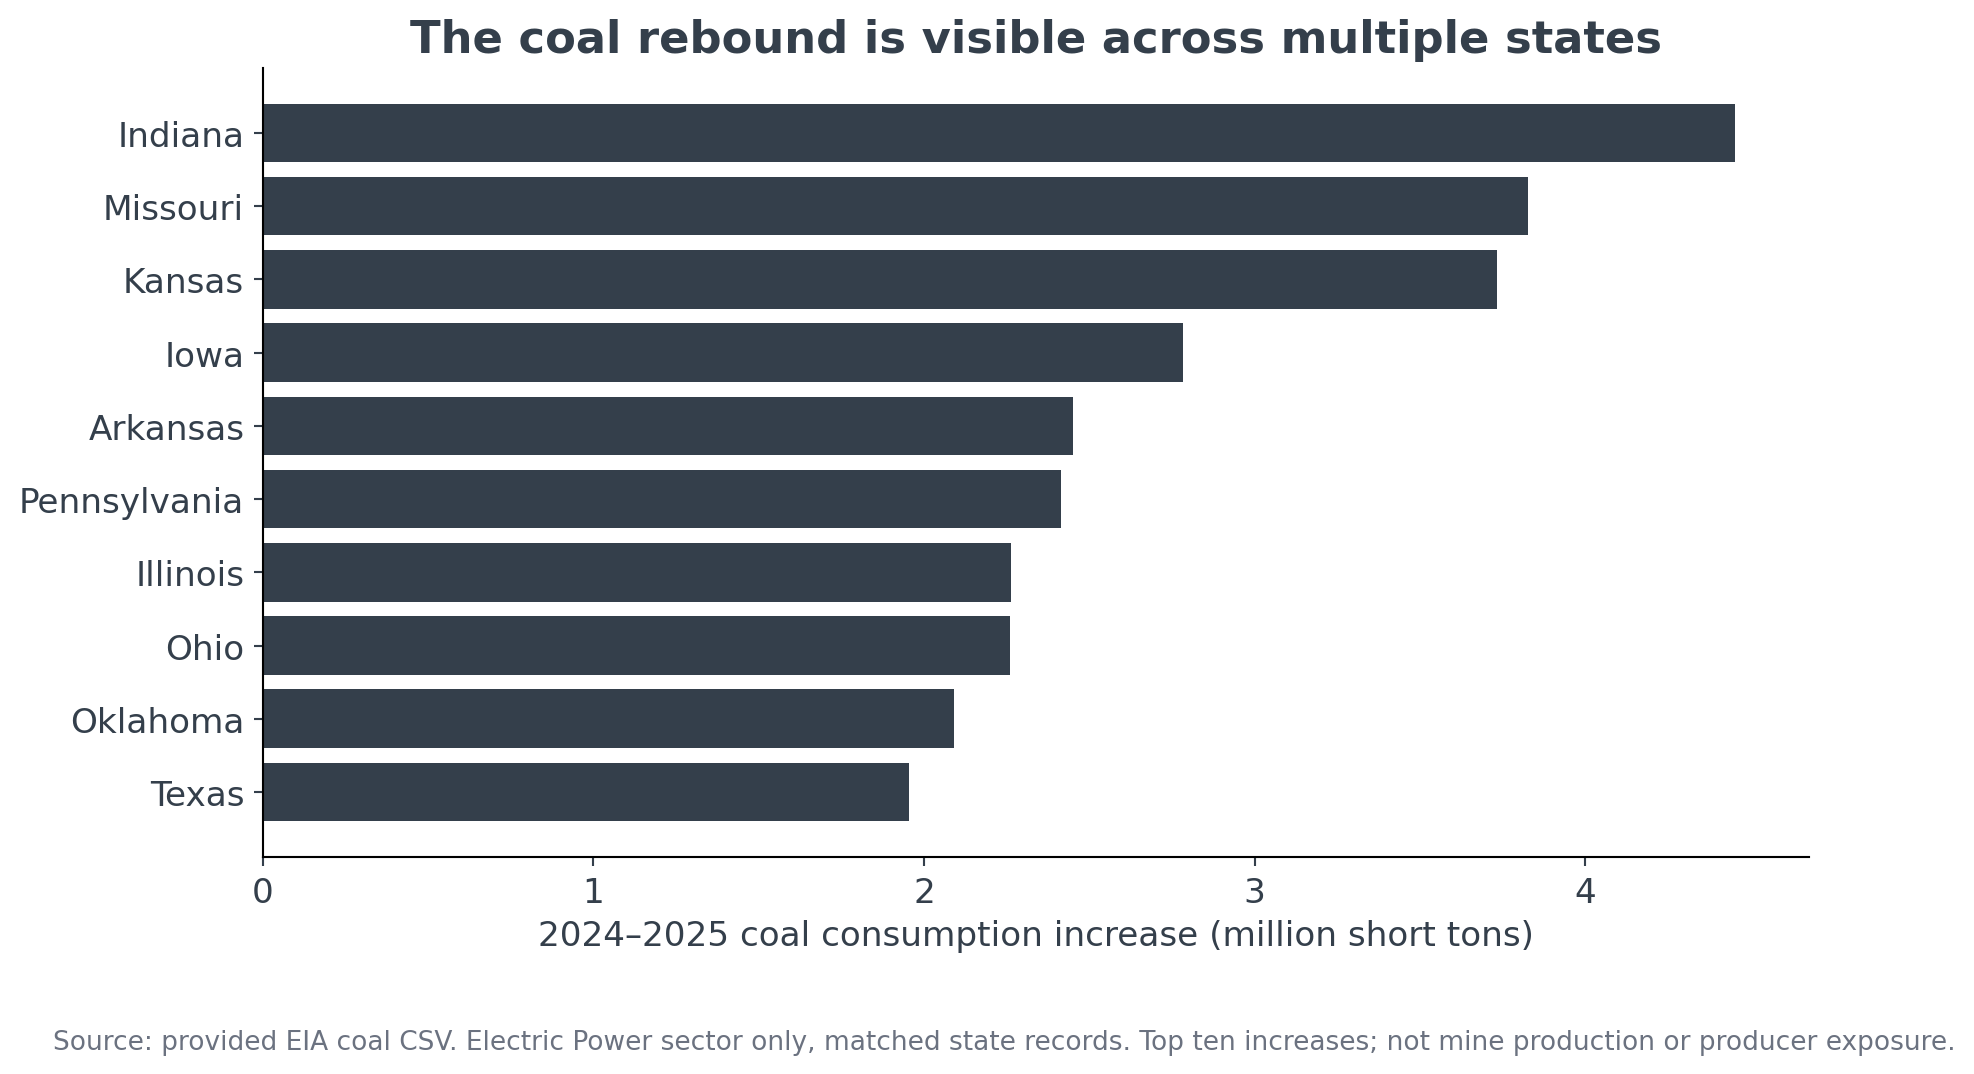

In [ ]:
state_pivot=state_coal.pivot(index=['location','stateDescription'],columns='period',values='consumption')
state_changes=state_pivot[[2024,2025]].dropna().copy()
state_changes['change_million_tons']=(state_changes[2025]-state_changes[2024])/1e6
state_changes=state_changes.sort_values('change_million_tons',ascending=False)
export_table(state_changes,'matched_state_coal_changes',index=True)
fig,ax=plt.subplots(figsize=(10.5,6.2))
top=state_changes.head(10).iloc[::-1]
ax.barh(top.index.get_level_values('stateDescription'),top.change_million_tons,color=COAL)
ax.set(xlabel='2024–2025 coal consumption increase (million short tons)',
    title='The coal rebound is visible across multiple states')
save(fig,'07_state_rebound_appendix','Source: provided EIA coal CSV. Electric Power sector only, matched state records. Top ten increases; not mine production or producer exposure.')



**Read this graph:** longer bars mean larger increases in coal burned by power plants between 2024 and 2025. These are the ten largest increases among states with records in both years.

**What it means:** the rebound appears in several states. This measures where coal was burned, rather than where it was mined, so it does not identify winning coal producers.

## Key numbers and sources

This cell saves exact calculations and input-file fingerprints, so a reviewer can reproduce the findings. The table below summarizes a few useful results.


In [ ]:
stats={
 'balanced_countries':len(panel_ids), 'panel_share_of_observed_2024_generation_pct':coverage_share,
 'naive_2025_fossil_change_pct':naive_fossil_change,
 'balanced_2025_fossil_change_pct':matched_fossil_change,
 'balanced_2020_2025_clean_change_pct':pct(global_panel.loc[2025,'clean_generation_twh'],global_panel.loc[2020,'clean_generation_twh']),
 'balanced_2020_2025_fossil_change_pct':pct(global_panel.loc[2025,'fossil_generation_twh'],global_panel.loc[2020,'fossil_generation_twh']),
 'us_2025_clean_gain_twh':latest_clean_gain,
 'us_2025_demand_gain_twh':float(us_power.loc[2025,'delta_demand_twh']),
 'us_2025_clean_demand_coverage_pct':float(100*latest_clean_gain/us_power.loc[2025,'delta_demand_twh']),
 'us_2025_fossil_gain_twh':float(us_power.loc[2025,'delta_fossil_generation_twh']),
 'us_coal_2025_growth_pct':pct(us_coal.loc[2025,'consumption'],us_coal.loc[2024,'consumption']),
 'us_coal_2025_vs_2020_pct':pct(us_coal.loc[2025,'consumption'],us_coal.loc[2020,'consumption']),
 'us_coal_2025_vs_2021_pct':pct(us_coal.loc[2025,'consumption'],us_coal.loc[2021,'consumption']),
 'us_coal_stocks_2025_growth_pct':pct(us_coal.loc[2025,'stocks'],us_coal.loc[2024,'stocks']),
 'us_inventory_days_2024':float(us_coal.loc[2024,'inventory_days_proxy']),
 'us_inventory_days_2025':float(us_coal.loc[2025,'inventory_days_proxy']),
 'us_scenario_break_even_demand_growth_pct':breakeven,
 'external_eia_coal_2025_change_twh':float(delta['Coal']),
 'external_eia_gas_2025_change_twh':float(delta['Natural Gas']),
 'external_eia_solar_2025_change_twh':float(delta['Solar Thermal and Photovoltaic'])}
(OUT/'key_numbers.json').write_text(json.dumps(stats,indent=2))
manifest={
 'project':'The Transition Has Two Speeds',
 'inputs':{p.name:{'sha256':hashlib.sha256(p.read_bytes()).hexdigest(),'bytes':p.stat().st_size}
    for p in [power_path,coal_path,third_path]},
 'versions':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'matplotlib':matplotlib.__version__},
 'scope':'Ember fixed 91-country panel; EIA coal US/sector98; external EIA all-industry national fuel mix.',
 'external_source':'https://www.eia.gov/electricity/data/state/',
 'external_file':'https://www.eia.gov/electricity/data/state/annual_generation_state.xlsx',
 'limitations':['No valuation or stock returns analyzed. No claim of market mispricing.',
    'Annual data do not establish hourly reliability, dispatch causation, or future profitability.',
    '2025 Ember coverage is incomplete; fixed panel is not the entire world.',
    'Heat content excluded: mislabeled units and inconsistent scales across sectors.',
    'Delivered coal prices are buyer costs, not producer margins. State consumption is not mining output.',
    'Missing prices preserved. National 2021 Electric Power price is unavailable.',
    'Inventory days proxy uses year-end stocks divided by historical annual consumption.',
    'Third-source EIA generation and Ember have different survey coverage; totals are kept separate.']}
(OUT/'provenance_and_limitations.json').write_text(json.dumps(manifest,indent=2))
headline_table = pd.DataFrame([
    ['Clean growth, 2020–2025 (91 countries)', f"{stats['balanced_2020_2025_clean_change_pct']:.1f}%"],
    ['Fossil growth, 2020–2025 (91 countries)', f"{stats['balanced_2020_2025_fossil_change_pct']:.1f}%"],
    ['U.S. coal-use change, 2025 vs 2024', f"{stats['us_coal_2025_growth_pct']:+.1f}%"],
    ['U.S. new demand covered by clean additions, 2025', f"{stats['us_2025_clean_demand_coverage_pct']:.1f}%"],
], columns=['Finding', 'Result'])
display(headline_table)
print(f'Finished. Charts, evidence tables and audit files are in {OUT}')


,Finding,Result
0,"Clean growth, 2020–2025 (91 countries)",34.1%
1,"Fossil growth, 2020–2025 (91 countries)",9.3%
2,"U.S. coal-use change, 2025 vs 2024",+11.3%
3,"U.S. new demand covered by clean additions, 2025",80.2%


Finished. Charts, evidence tables and audit files are in /content/outputs


## Extra: your four-panel summary

This keeps your additional calculations and puts four charts together. Use the individual charts above for large presentation slides; this combined image gives the team a quick overview.

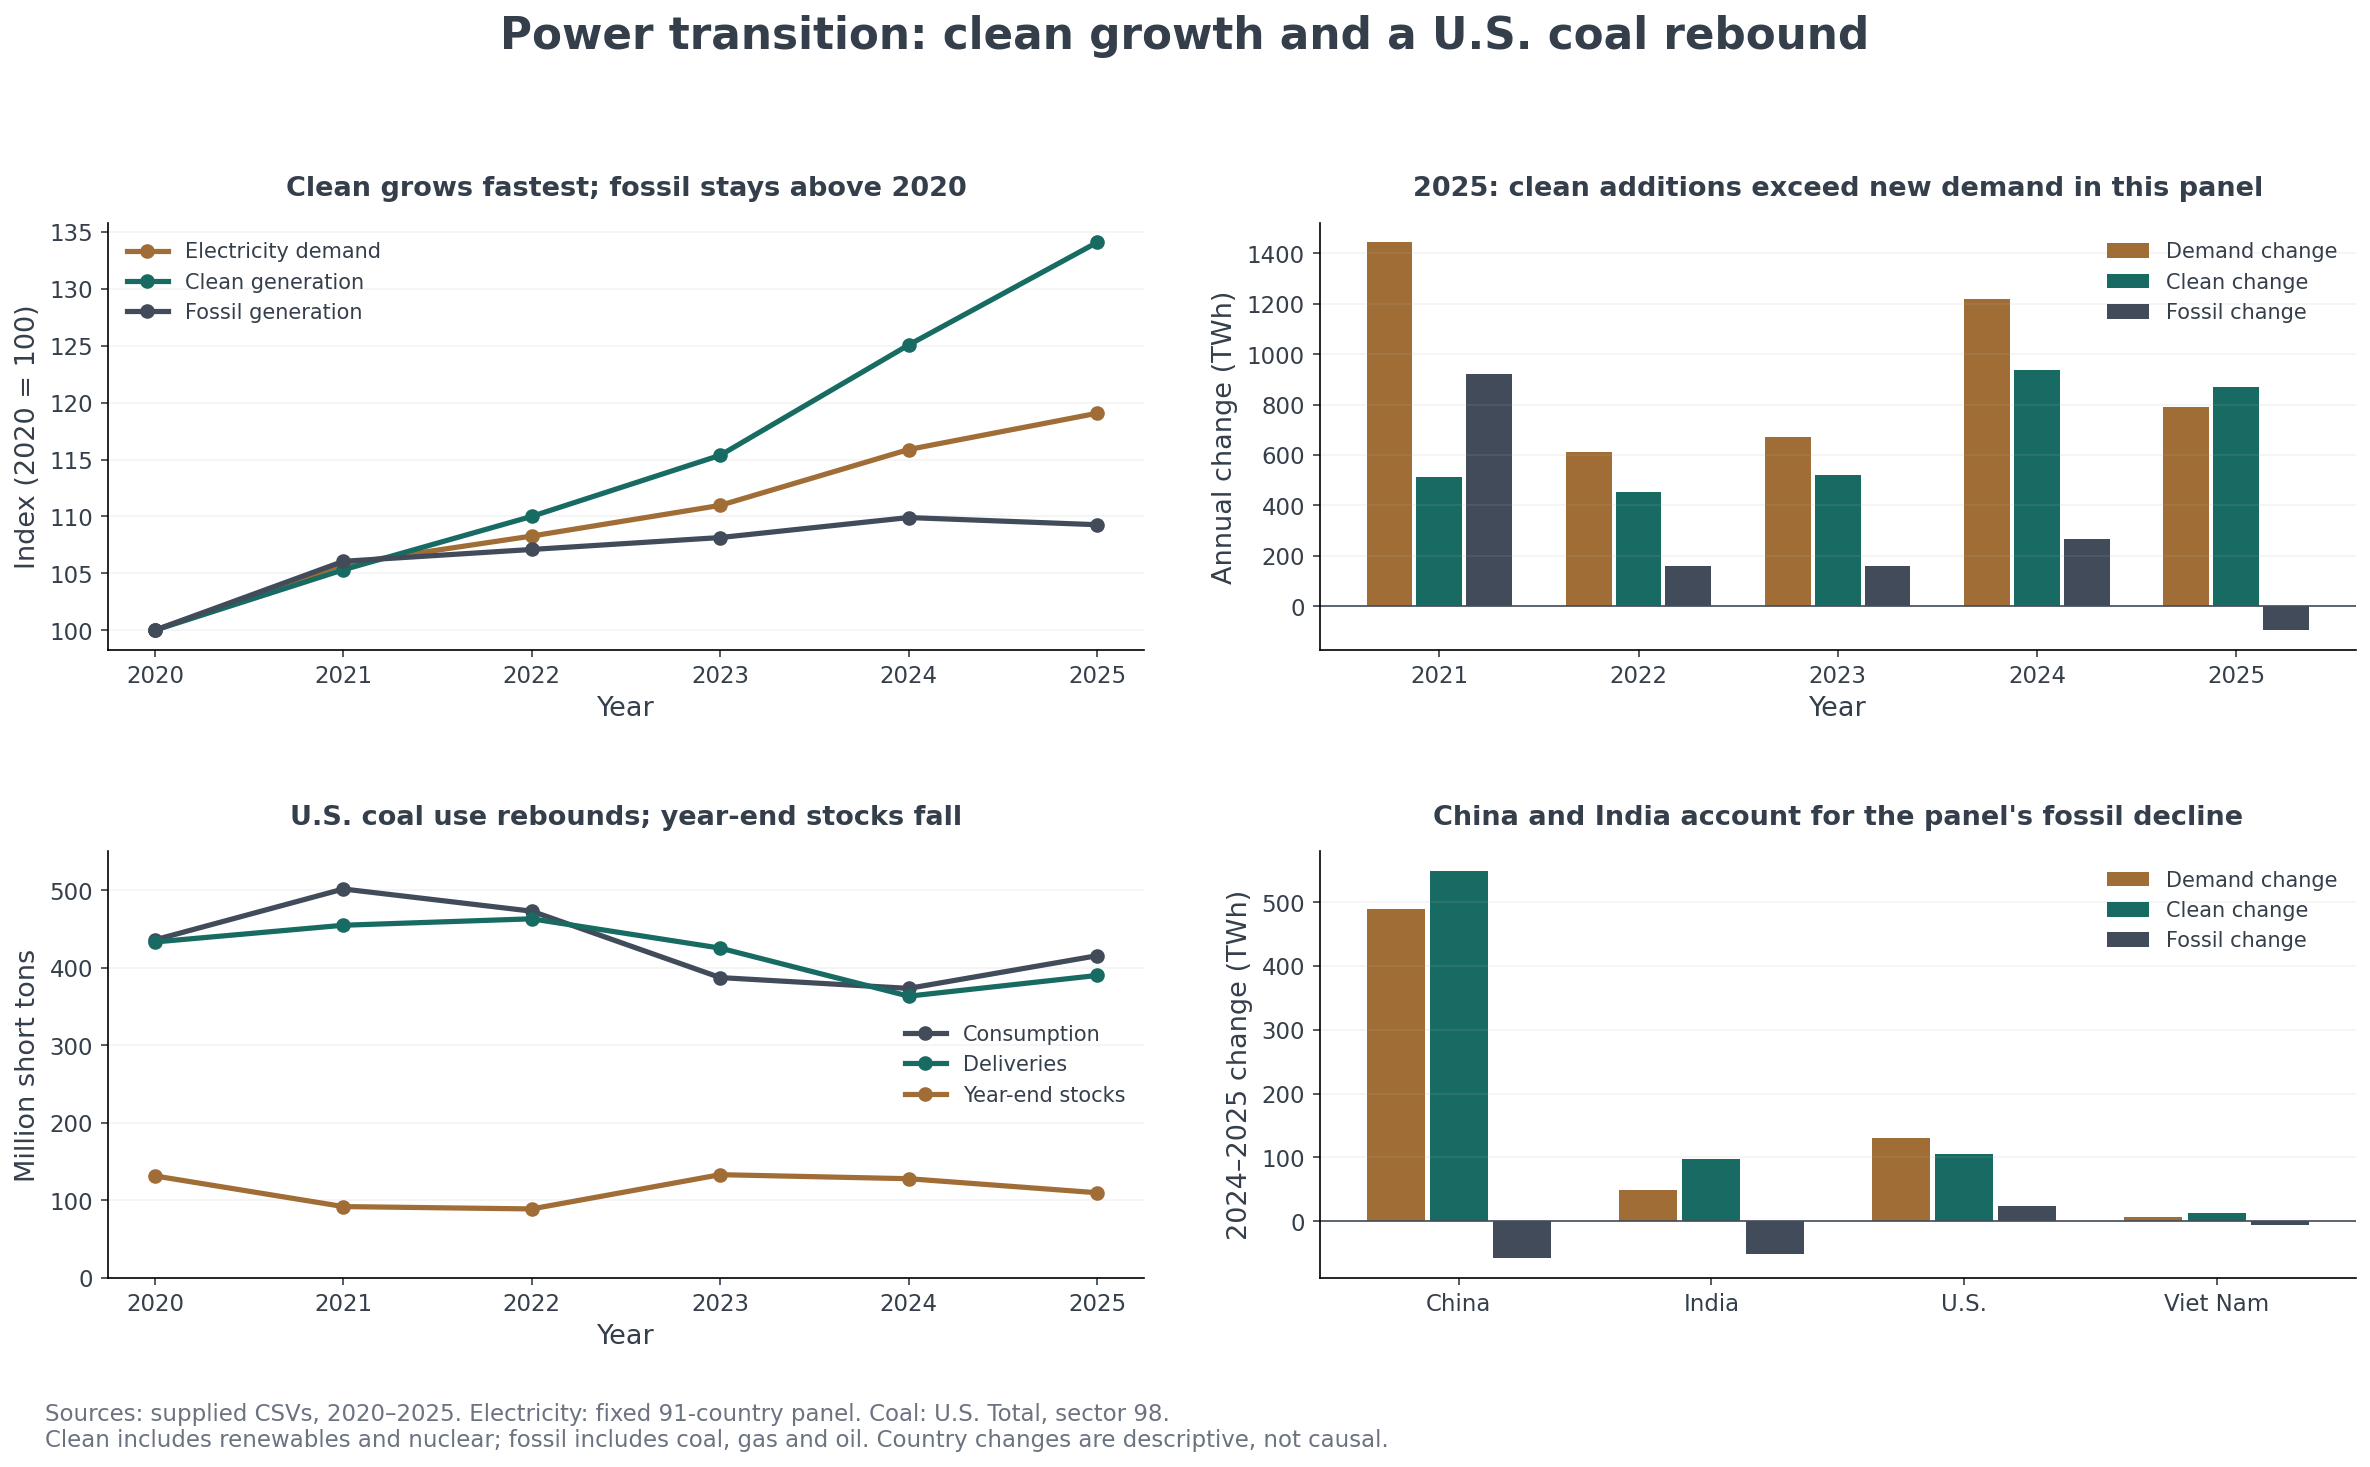

Panel fossil change excluding China and India: +13.97 TWh.
Summary data tables and metrics were saved in outputs/.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
from IPython.display import display, Image as NotebookImage

summary_root = Path.cwd()
out = summary_root / 'outputs'
out.mkdir(exist_ok=True)

def summary_csv(name):
    for folder in [summary_root / 'data', summary_root, Path('/content')]:
        candidate = folder / name
        if candidate.is_file():
            return candidate
    raise FileNotFoundError('Upload ' + name + ', then run this cell again.')

a = pd.read_csv(summary_csv('country_year_electricity_2020_2025.csv'))
b = pd.read_csv(summary_csv('eia_coal_consumption_quality_2020_2025.csv'), dtype={'location':str})
assert not a.duplicated(['iso3', 'year']).any()
assert not b.duplicated(['period', 'location', 'sector']).any()
ids = a[a.year.between(2020, 2025)].groupby('iso3').year.nunique()
p = a[a.iso3.isin(ids[ids.eq(6)].index) & a.year.between(2020, 2025)].copy()
cols = ['demand_twh', 'generation_twh', 'clean_generation_twh',
        'fossil_generation_twh', 'wind_solar_generation_twh', 'power_emissions_mtco2e']
g = p.groupby('year')[cols].sum(min_count=1)
g['clean_share_pct'] = 100 * g.clean_generation_twh / g.generation_twh
demand_increase = g.demand_twh.diff()
g['clean_growth_coverage_pct'] = (100 * g.clean_generation_twh.diff()
                                 / demand_increase.where(demand_increase.gt(0)))
g['carbon_intensity_gco2e_kwh'] = 1000 * g.power_emissions_mtco2e / g.generation_twh
electricity_summary = g.copy()
g.to_csv(out / 'balanced_electricity_summary.csv')

c = b[b.location.eq('US') & b.sector.eq(98)].set_index('period').sort_index().copy()
c['inventory_days_proxy'] = 365 * c.stocks / c.consumption.where(c.consumption.gt(0))
c['consumption_yoy_pct'] = 100 * c.consumption.pct_change(fill_method=None)
c.to_csv(out / 'us_power_coal_summary.csv')
w = p.pivot(index=['iso3', 'country'], columns='year', values=cols)
r = pd.DataFrame({key:w[key][2025] - w[key][2024] for key in cols})
r['clean_growth_coverage_pct'] = (100 * r.clean_generation_twh
                                 / r.demand_twh.where(r.demand_twh.gt(0)))
r.to_csv(out / 'country_changes_2025.csv')

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
palette = ['#A16D36', '#176B63', '#414B5A']
for col, label, color in zip(
        ['demand_twh', 'clean_generation_twh', 'fossil_generation_twh'],
        ['Electricity demand', 'Clean generation', 'Fossil generation'], palette):
    axes[0, 0].plot(g.index, 100 * g[col] / g[col].iloc[0],
                    label=label, color=color, marker='o', linewidth=2.5)
axes[0, 0].set(title='Clean grows fastest; fossil stays above 2020',
                ylabel='Index (2020 = 100)', xlabel='Year')

annual = g[['demand_twh', 'clean_generation_twh', 'fossil_generation_twh']].diff().iloc[1:]
positions = np.arange(len(annual))
for j, (col, label, color) in enumerate(zip(
        annual.columns, ['Demand change', 'Clean change', 'Fossil change'], palette)):
    axes[0, 1].bar(positions + (j - 1) * .25, annual[col],
                    width=.23, label=label, color=color)
axes[0, 1].set(xticks=positions, xticklabels=annual.index,
                ylabel='Annual change (TWh)', xlabel='Year',
                title='2025: clean additions exceed new demand in this panel')
axes[0, 1].axhline(0, color='#414B5A', linewidth=.8)

for col, label, color in zip(['consumption', 'receipts', 'stocks'],
        ['Consumption', 'Deliveries', 'Year-end stocks'], ['#414B5A', '#176B63', '#A16D36']):
    axes[1, 0].plot(c.index, c[col] / 1e6, label=label, color=color,
                    marker='o', linewidth=2.5)
axes[1, 0].set(title='U.S. coal use rebounds; year-end stocks fall',
                ylabel='Million short tons', xlabel='Year', ylim=(0, 550))

selected = r.loc[[('CHN', 'China'), ('IND', 'India'),
                   ('USA', 'United States of America'), ('VNM', 'Viet Nam')]]
positions = np.arange(len(selected))
for j, (col, label, color) in enumerate(zip(
        ['demand_twh', 'clean_generation_twh', 'fossil_generation_twh'],
        ['Demand change', 'Clean change', 'Fossil change'], palette)):
    axes[1, 1].bar(positions + (j - 1) * .25, selected[col],
                    width=.23, label=label, color=color)
axes[1, 1].set(xticks=positions, xticklabels=['China', 'India', 'U.S.', 'Viet Nam'],
                ylabel='2024–2025 change (TWh)',
                title="China and India account for the panel's fossil decline")
axes[1, 1].axhline(0, color='#414B5A', linewidth=.8)

for axis in axes.flat:
    axis.grid(axis='y', alpha=.15)
    axis.legend(frameon=False, fontsize=10, loc='best')
    axis.tick_params(labelsize=11)
    axis.set_title(axis.get_title(), fontsize=13, pad=13)
fig.suptitle('Power transition: clean growth and a U.S. coal rebound',
             fontsize=21, fontweight='bold', y=.98)
fig.tight_layout(rect=(0, .07, 1, .94), h_pad=3, w_pad=2.5)
fig.text(.025, .025, 'Sources: supplied CSVs, 2020–2025. Electricity: fixed 91-country panel. Coal: U.S. Total, sector 98.\n'
         'Clean includes renewables and nuclear; fossil includes coal, gas and oil. Country changes are descriptive, not causal.',
         fontsize=11, color='#6B7280')
fig.savefig(out / 'energy_thesis_charts.png', dpi=150, bbox_inches='tight')
plt.close(fig)
display(NotebookImage(filename=str(out / 'energy_thesis_charts.png'), width=1200))

volume_changes = (100 * (g.loc[2025, cols] / g.loc[2020, cols] - 1)).to_dict()
metrics = {
    'countries':int(len(ids[ids.eq(6)])),
    'coverage_2024_pct':float(100 * g.loc[2024, 'generation_twh'] / a[a.year.eq(2024)].generation_twh.sum()),
    'change_2020_2025_pct':volume_changes,
    'clean_share_change_pp':float(g.loc[2025, 'clean_share_pct'] - g.loc[2020, 'clean_share_pct']),
    'coal_2025':json.loads(c.loc[2025].to_json()),
}
(out / 'metrics.json').write_text(json.dumps(metrics, indent=2, allow_nan=False))
rest_fossil_change = (r.fossil_generation_twh.sum()
                     - r.loc[('CHN', 'China'), 'fossil_generation_twh']
                     - r.loc[('IND', 'India'), 'fossil_generation_twh'])
print(f'Panel fossil change excluding China and India: {rest_fossil_change:+.2f} TWh.')
print('Summary data tables and metrics were saved in outputs/.')


**Read the four panels:** top-left compares long-term growth; top-right compares annual additions; bottom-left shows the U.S. coal rebound; bottom-right compares selected countries.

**What it means:** the fixed panel's fossil decline in 2025 is concentrated in China and India. Other countries in the panel together had a small increase. A panel-level improvement can coexist with a U.S. coal rebound.

## Extra: clean share and emissions intensity

Clean share means the percentage of electricity produced from clean sources. Carbon intensity means emissions per unit of electricity. Correlation summarizes how they move together.

In [ ]:
import pandas as pd
from IPython.display import display

if 'electricity_summary' not in globals():
    raise RuntimeError('Run the four-panel summary cell above this cell first.')
correlation_pairs = electricity_summary[
    ['clean_share_pct', 'carbon_intensity_gco2e_kwh']].dropna()
if len(correlation_pairs) < 3 or correlation_pairs.nunique().lt(2).any():
    raise ValueError('Correlation needs at least three complete rows and variation in both measures.')
correlation = correlation_pairs.clean_share_pct.corr(
    correlation_pairs.carbon_intensity_gco2e_kwh)
print(f'Pearson correlation: {correlation:.4f} across {len(correlation_pairs)} annual observations.')
print('A negative value means these measures moved in opposite directions.')
print('This six-year association does not establish causation or predictive accuracy.')
display(correlation_pairs.round(2))
correlation_pairs.to_csv(Path.cwd() / 'outputs' / 'clean_share_and_carbon_intensity.csv')


Pearson correlation: -0.9976 across 6 annual observations.
A negative value means these measures moved in opposite directions.
This six-year association does not establish causation or predictive accuracy.


,clean_share_pct,carbon_intensity_gco2e_kwh
year,,
2020,38.84,486.81
2021,38.68,490.68
2022,39.48,484.72
2023,40.39,477.88
2024,41.96,465.54
2025,43.80,451.53


**Read the result:** correlation ranges from −1 to +1. The value near −1 means higher clean share coincided with lower emissions per unit of electricity across these six years.

**Important limit:** these are only six annual observations from the same country panel. The measures are also related through the generation mix, so this is supporting description rather than independent proof that an investment will perform well.

## Download all results

This is the final step. Run it after the analysis and extra summary cells. It downloads one ZIP containing the charts, supporting tables, key numbers and source information.

This cell finds the output folder directly, so it also works after a session reset if the generated files are still present. If Colab has deleted those files, run all cells again.


In [ ]:
from pathlib import Path
import shutil

download_root = Path.cwd()
download_out = download_root / 'outputs'
if not download_out.is_dir() or not any(download_out.iterdir()):
    raise FileNotFoundError('No saved results were found. Run the notebook from the top to create the graphs and tables.')
archive = shutil.make_archive(str(download_root / 'energy_analysis_outputs'), 'zip',
                              root_dir=download_out)
print('Created energy_analysis_outputs.zip with all current results.')
try:
    from google.colab import files
except ImportError:
    print('Local download file:', archive)
else:
    files.download(archive)


Created energy_analysis_outputs.zip with all current results.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>